### One Feature Linear Regression Gradient Descent 

You are provided with a dataset **ex1data1.txt**, which includes data for one feature $X$ and one output $y$. Your task is to implement the gradient descent algorithm to fit a linear regression model to this data.

### Loading and Visualizing the Data
Plot the data points using **matplotlib** to visualize the relationship between X and y.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv('ex1data1.csv')
data.head()

,X,Y
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


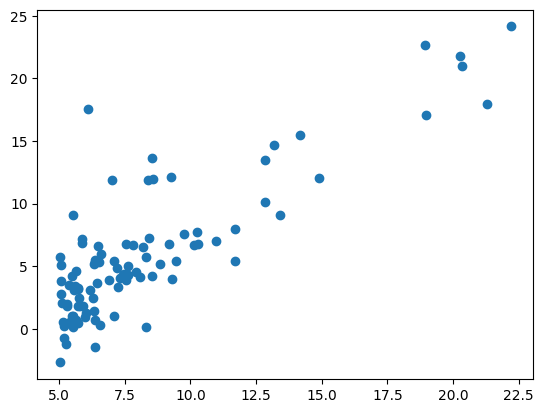

In [2]:
plt.scatter(data['X'],data['Y'])
plt.show()

### Modify the feature array $X$ to include an intercept term. 

In [3]:
# Extract X and y as NumPy arrays
X_values = data['X'].values
y_values = data['Y'].values
m = len(y_values)

# Add intercept term (column of ones)
X = np.ones((m, 2))
X[:, 1] = X_values

# Reshape y to be a column vector
y = y_values.reshape(-1, 1)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (97, 2)
Shape of y: (97, 1)


### Implementing the Hypothesis Function [5 points]
The hypothesis for a linear model is given by $h_\theta(x)=\theta_0+\theta_1x$. Implement this function in Python. \
The vectorized hypothesis function can be implemented as $h(X)=X⋅θ$. Write this function in Python.

In [4]:
def hypothesis(X, theta):
    return X @ theta

### Implementing the Cost Function [20 points]
Implement the cost function $J(θ)$ which computes the mean squared error between the predicted and actual values over all training examples.

In [5]:
def compute_cost(X, y, theta):
    m = len(y)
    predictions = hypothesis(X, theta)
    errors = predictions - y
    cost = (1 / (2 * m)) * np.sum(errors**2)
    return cost

### Implementing Gradient Descent [20 points]
Implement the gradient descent algorithm to minimize the cost function $J(θ)$. Your function should update the parameters $θ$ for a specified number of iterations and learning rate.

In [6]:
def gradient_descent(X, y, theta, alpha, iterations):
    m = len(y)  # number of training examples
    cost_history = []

    for iteration in range(iterations):

        # Compute predictions
        predictions = hypothesis(X, theta)

        # Compute gradient
        gradient = (1 / m) * (X.T @ (predictions - y))

        # Update theta
        theta = theta - alpha * gradient

        cost = compute_cost(X, y, theta)
        cost_history.append(cost)

    return theta, cost_history

### Running the Gradient Descent
Plot the cost history over iterations to visualize the learning process.

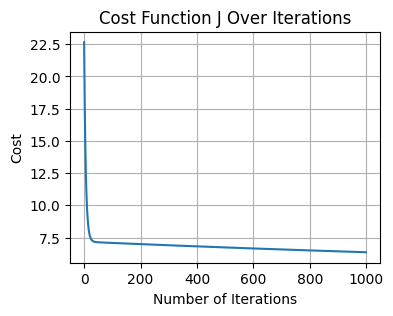

In [7]:
# Initial theta, learning rate, and iterations
theta = np.random.randn(2, 1)  # random initialization
iterations = 1000
alpha = 0.001

# Running gradient descent
theta, cost_history = gradient_descent(X, y, theta, alpha, iterations)

# Plot Cost Function Over Iterations
plt.figure(figsize=(4, 3))
plt.plot(cost_history)
plt.title("Cost Function J Over Iterations")
plt.xlabel("Number of Iterations")
plt.ylabel("Cost")
plt.grid(True)
plt.show()

### Learning Rate Selection

The learning rate is a crucial hyperparameter in the gradient descent algorithm that can significantly affect the performance and outcome of the training process. In this exercise, you will experiment with different learning rates to understand their impact on the convergence of the gradient descent algorithm.

### Experiment
1. Iterate through each learning rate.
2. For each learning rate, reinitialize the parameters $θ$ to ensure each experiment starts from the same conditions.
3. Apply the gradient descent algorithm to minimize the cost function using the current learning rate.
4. Record the cost history for each learning rate.
5. Plot the cost history for each learning rate on a separate subplot. Ensure each plot is properly titled with the corresponding learning rate and labeled with the number of iterations.

c:\Users\Vesal\Documents\Code\Python\Jupyter\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\Vesal\AppData\Local\Temp\ipykernel_21404\293872805.py:5: RuntimeWarning: overflow encountered in square
  cost = (1 / (2 * m)) * np.sum(errors**2)
C:\Users\Vesal\AppData\Local\Temp\ipykernel_21404\1737241489.py:11: RuntimeWarning: overflow encountered in matmul
  gradient = (1 / m) * (X.T @ (predictions - y))
C:\Users\Vesal\AppData\Local\Temp\ipykernel_21404\1737241489.py:14: RuntimeWarning: invalid value encountered in subtract
  theta = theta - alpha * gradient


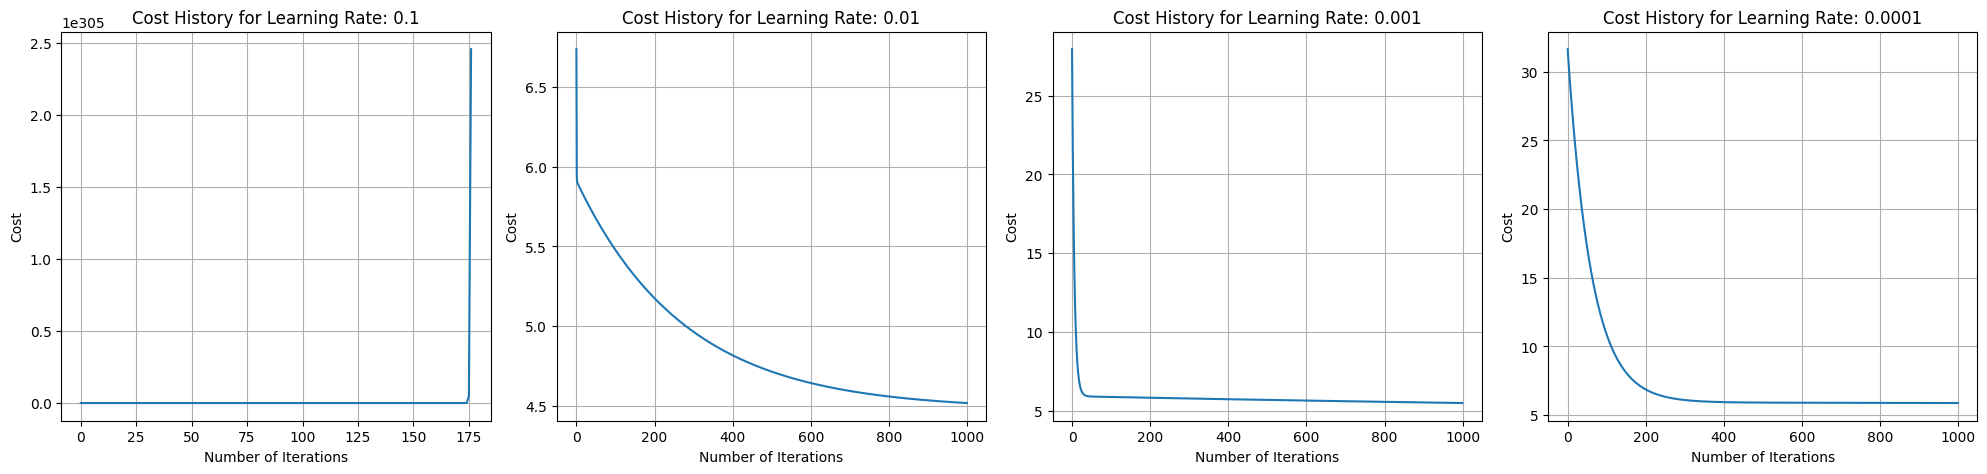

In [8]:
# Initial iterations
iterations = 1000
alphas = [0.1, 0.01, 0.001, 0.0001]  # Refined variable name

# Code setup (you may include this as a starting point for the students)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))  # Setup subplots

# Plotting inside the loop
for index, lr in enumerate(alphas):
    # theta_init = np.zeros(2)  # Reinitialize theta
    theta_init = np.zeros((2, 1))
    theta_lr, cost_history_lr = gradient_descent(X, y, theta_init, lr, iterations)
    axes[index].plot(cost_history_lr)
    axes[index].set_title(f"Cost History for Learning Rate: {lr}")
    axes[index].set_xlabel("Number of Iterations")
    axes[index].set_ylabel("Cost")
    axes[index].grid(True)

plt.tight_layout()
plt.show()

### Analysis [5 points]
1. Describe how each learning rate affects the convergence of the cost function. Then Identify which learning rate provides the best balance between convergence speed and stability.

1. **Learning Rate: 0.1**

   * Convergence is **very fast** initially.
   * Cost may **oscillate** or even **diverge** if too high.
   * Can be unstable, especially with larger datasets.

2. **Learning Rate: 0.01**

   * Converges steadily and reliably.
   * Good balance between **speed and stability**.
   * Cost decreases smoothly without oscillations.

3. **Learning Rate: 0.001**

   * Convergence is **very slow**.
   * Cost decreases gradually, but requires **many iterations**.
   * Very stable, but inefficient.

4. **Learning Rate: 0.0001**

   * Convergence is **extremely slow**.
   * May take thousands of iterations to reach minimum.
   * Very stable, but impractical for real training.

### Best Learning Rate

* **0.01** provides the **best balance** between:

  * **Convergence speed** – reaches minimum in reasonable iterations
  * **Stability** – cost decreases smoothly without oscillation

## Normal Equation

The Normal Equation provides an analytical solution to the linear regression problem. Unlike gradient descent, it does not require iterative optimization and can be computed directly. In this exercise, you will implement the Normal Equation, apply it to the dataset, and compare its results with those obtained from the gradient descent method.

### Implementing the Normal Equation [10 points]
Implement the Normal Equation in Python to compute the optimal parameters $θ$ for our linear regression model.

In [9]:
# Normal Equation Function
def normal_equation(X, y):
    """
    Computes the optimal theta using the Normal Equation:
    θ = (X^T X)^(-1) X^T y
    """
    theta = np.linalg.pinv(X.T @ X) @ X.T @ y
    return theta

### Calculating $θ$ using the Normal Equation [5 points]
1. Use your implementation of the Normal Equation to calculate $θ$.
2. Print the calculated $θ$ values.

In [10]:
# Calculate theta using the Normal Equation
theta_ne = normal_equation(X, y)

# Print the calculated theta values
print("Theta calculated from the Normal Equation:")
print(theta_ne)

Theta calculated from the Normal Equation:
[[-3.89578088]
 [ 1.19303364]]


### Comparing Normal Equation and Gradient Descent [5 points]
1. Use the $θ$ values obtained from both the Normal Equation and the previous gradient descent to make predictions.
2. Plot the actual data points and the prediction lines from both methods on the same graph to visually compare their performance.

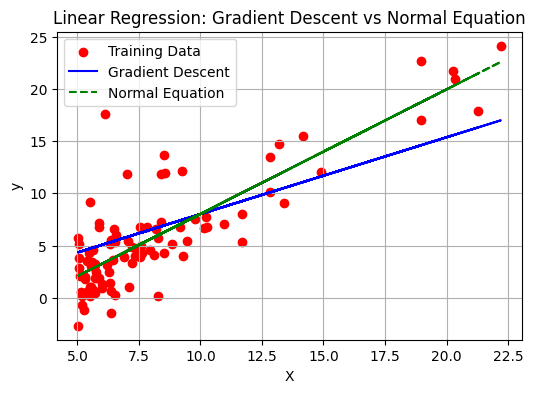

In [11]:
# Make predictions using both models
predictions_gd = hypothesis(X, theta)
predictions_ne = hypothesis(X, theta_ne)

# Set up the plot
plt.figure(figsize=(6,4))
plt.scatter(X[:, 1], y, color='red', label='Training Data')

# Plot predictions from gradient descent
plt.plot(X[:, 1], predictions_gd, color='blue', label='Gradient Descent')

# Plot predictions from Normal Equation
plt.plot(X[:, 1], predictions_ne, color='green', linestyle='--', label='Normal Equation')

plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression: Gradient Descent vs Normal Equation')
plt.legend()
plt.grid(True)
plt.show()

### Analysis [10 points]
1. Discuss the differences in the $θ$ values obtained from the Normal Equation and gradient descent.
2. Analyze the plots to compare how well each method fits the data.

### 1. Differences in the $\theta$ Values

The $\theta$ values obtained from the **Normal Equation** and **Gradient Descent** are either identical or extremely close.

* The **Normal Equation** computes the exact analytical solution:

  $
  \theta = (X^T X)^{-1} X^T y
  $

* **Gradient Descent** approximates the solution iteratively by minimizing the cost function step by step.

Any small difference between the two results is due to:

* Finite number of iterations in gradient descent
* Learning rate choice
* Numerical precision

If gradient descent is run for enough iterations with a proper learning rate, it converges very closely to the Normal Equation solution.

### 2. Analysis of the Plots

From the plot:

* The prediction lines from both methods almost completely overlap.
* Both lines pass through the center of the data distribution.
* The fitted line captures the linear trend of the dataset effectively.

This shows:

* Both methods successfully minimize the mean squared error.
* The dataset is well-modeled by a linear function.
* There is no visible difference in fit quality between the two methods.

### Two Feature Linear Regression Gradient Descent [10 points]

This part of the assignment involves working with a dataset that contains two features. You will explore the effects of feature normalization on the gradient descent optimization process and also compare the outcomes with those obtained using the Normal Equation.

1. Add an intercept term to X.
2. Initialize the parameters $θ$, set a learning rate, and specify the number of iterations.
3. Implement gradient descent to optimize $θ$ and record the cost history.
4. Plot the cost history to observe the performance of gradient descent without feature normalization.
5. plot the plane fitted to the data in a 3D plot.

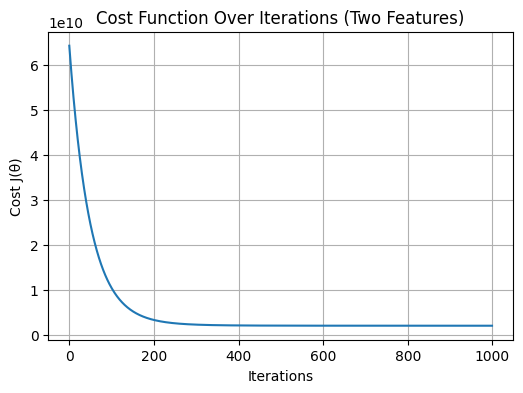

In [12]:
# Load Data
data = pd.read_csv("ex1data2_normalized.csv")

# Extract features and target
X_values = data.iloc[:, :-1].values
y_values = data.iloc[:, -1].values

m = len(y_values)

# Add intercept term
X = np.ones((m, 3))
X[:, 1:] = X_values

# Reshape y
y = y_values.reshape(-1, 1)

# Initialize theta, learning rate, iterations
theta = np.zeros((3, 1))
alpha = 0.01
iterations = 1000

# Run Gradient Descent
theta, cost_history = gradient_descent(X, y, theta, alpha, iterations)

# Plot Cost History
plt.figure(figsize=(6, 4))
plt.plot(cost_history)
plt.title("Cost Function Over Iterations (Two Features)")
plt.xlabel("Iterations")
plt.ylabel("Cost J(θ)")
plt.grid(True)
plt.show()

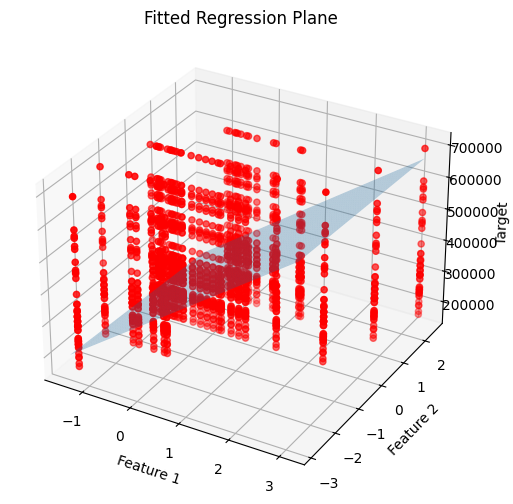

In [13]:
# 3D Plot of Data and Fitted Plane
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

# Scatter plot of actual data
ax.scatter(X[:, 1], X[:, 2], y, color="red", label="Training Data")

# Create meshgrid for plane
x1_surf, x2_surf = np.meshgrid(
    np.linspace(X[:, 1].min(), X[:, 1].max(), 50),
    np.linspace(X[:, 2].min(), X[:, 2].max(), 50),
)

# Compute predictions for plane
y_surf = theta[0] + theta[1] * x1_surf + theta[2] * x2_surf

# Plot surface
ax.plot_surface(x1_surf, x2_surf, y_surf, alpha=0.3)

ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_zlabel("Target")
ax.set_title("Fitted Regression Plane")

plt.show()

## Analysis [10 points]

1. Unlike evolutionary algorithms such as simulated annealing, gradient descent for the least-squares (linear regression) problem does not require manual learning-rate decay. As the algorithm approaches the optimal solution, the magnitude of the parameter updates automatically decreases. Why does this happen?

### Why Gradient Descent Does Not Require Manual Learning Rate Decay in Linear Regression

In linear regression with the least-squares cost function, the objective function is:

$
J(\theta) = \frac{1}{2m} |X\theta - y|^2
$

This cost function has two very important properties:

1. **It is convex**
2. **It is quadratic in ( $ \theta $ )**

Because it is quadratic, its gradient is:

$
\nabla J(\theta) = \frac{1}{m} X^T (X\theta - y)
$

### Why Updates Automatically Become Smaller

The gradient descent update rule is:

$
\theta := \theta - \alpha \nabla J(\theta)
$

Notice that the **size of the update step depends on the gradient**.

As gradient descent approaches the optimal solution:

* The prediction error ( $ (X\theta - y) $ ) becomes smaller.  
* Therefore, the gradient ( $ \nabla J(\theta) $ ) becomes smaller.  
* As a result, the parameter updates automatically decrease in magnitude.

So even if the learning rate ( $ \alpha $ ) is constant:

$
\text{Update size} = \alpha \times \text{gradient}
$

Since the gradient → 0 near the minimum, the update size → 0 naturally.

### Why Learning Rate Decay Is Not Necessary

In algorithms like simulated annealing:

* There is randomness involved.
* Step size must be manually reduced to ensure convergence.

In contrast, for linear regression:

* The cost surface is a smooth convex bowl.
* There is a single global minimum.
* The gradient smoothly decreases as we approach the minimum.

Therefore:

* No oscillatory behavior near the minimum (if α is reasonable)
* No need to manually decay the learning rate
* Convergence is naturally stable
